<a href="https://colab.research.google.com/github/lenoso1/DS471-project/blob/main/DS471_Obesity_Level_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Obesity Level Prediction Using Machine Learning

**Course:** DS471 – Machine Learning

**Project Objective:** This project aims to predict obesity levels using eating habits and physical characteristics. Three machine-learning models will be developed and compared: Logistic Regression, Random Forest, and a Neural Network.


## Stage 1: Data Cleaning, Preparation and Exploration

### Dataset Description


The Obesity Level dataset contains 2,111 records and 17 columns, including 16 input features and one target variable (NObeyesdad).

The features describe personal characteristics, eating habits, and physical activity. The target contains seven obesity categories, making this a multiclass classification problem.

After removing 24 duplicate records, 2,087 records remained for model development. The dataset includes original and synthetic observations.


In [1]:

import pandas as pd

# Load the dataset directly from GitHub
dataset_url = "https://raw.githubusercontent.com/lenoso1/DS471-project/main/ObesityDataSet_raw_and_data_sinthetic.csv"

df = pd.read_csv(dataset_url)

# Display dataset information
print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (2111, 17)


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


### Data Quality Checks

We examine the dataset to identify missing values, duplicate records, inconsistent data, and data types. We also check the distribution of obesity levels before preparing the data for machine learning.

In [2]:
# Check the dataset structure and data types
print("Dataset information:")
df.info()

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate rows:", df.duplicated().sum())

# Check target class distribution
print("\nObesity level distribution:")
print(df["NObeyesdad"].value_counts())

# Check categorical values for inconsistencies
print("\nCategorical feature values:")
for column in df.select_dtypes(include=["object", "category"]).columns:
    print(f"\n{column}:")
    print(df[column].value_counts(dropna=False))

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2111 non-null   object 
 1   Age                             2111 non-null   float64
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   family_history_with_overweight  2111 non-null   object 
 5   FAVC                            2111 non-null   object 
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   CAEC                            2111 non-null   object 
 9   SMOKE                           2111 non-null   object 
 10  CH2O                            2111 non-null   float64
 11  SCC                             2111 non-null   object 
 12  FAF          


### Duplicate and Data Consistency Analysis

The dataset contains 24 exact duplicate records and no missing values. Before removing duplicates, we check whether identical feature values have different obesity-level labels.


In [3]:

# Check whether identical features have conflicting labels
feature_columns = df.columns.drop("NObeyesdad")

conflicting_labels = (
    df.groupby(list(feature_columns), dropna=False)["NObeyesdad"]
    .nunique()
)

print("Feature combinations with conflicting labels:",
      (conflicting_labels > 1).sum())

print("Exact duplicate rows:", df.duplicated().sum())


Feature combinations with conflicting labels: 0
Exact duplicate rows: 24



### Duplicate Removal

The dataset contains 24 exact duplicate records. No conflicting class labels were found for identical feature values. Therefore, we remove the duplicate records before splitting the data to prevent repeated observations from affecting model evaluation.


In [4]:

# Remove exact duplicate records
df = df.drop_duplicates().reset_index(drop=True)

# Verify the results
print("Dataset shape after cleaning:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())


Dataset shape after cleaning: (2087, 17)
Remaining duplicates: 0



### Outlier Detection

We use the Interquartile Range (IQR) method to identify possible outliers in the numerical features. These values will be examined before deciding whether any changes are necessary.


In [5]:

# Identify possible outliers using the IQR method
numeric_columns = df.select_dtypes(include="number").columns

Q1 = df[numeric_columns].quantile(0.25)
Q3 = df[numeric_columns].quantile(0.75)
IQR = Q3 - Q1

outliers = (
    (df[numeric_columns] < (Q1 - 1.5 * IQR)) |
    (df[numeric_columns] > (Q3 + 1.5 * IQR))
)

print("Possible outliers by feature:")
print(outliers.sum().sort_values(ascending=False))


Possible outliers by feature:
NCP       577
Age       167
Weight      1
Height      1
FCVC        0
CH2O        0
FAF         0
TUE         0
dtype: int64



### Outlier Handling

The IQR method identified 577 possible outliers in NCP, 167 in Age, and one each in Height and Weight. However, these values are not necessarily incorrect. NCP represents meal frequency, while differences in age, height, and weight may reflect natural variation between individuals.

Therefore, no records were removed based only on the IQR results. The observations are retained to avoid losing potentially useful information for predicting obesity levels.



### Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand the patterns and relationships in the dataset. We begin by examining the distribution of the seven obesity levels.


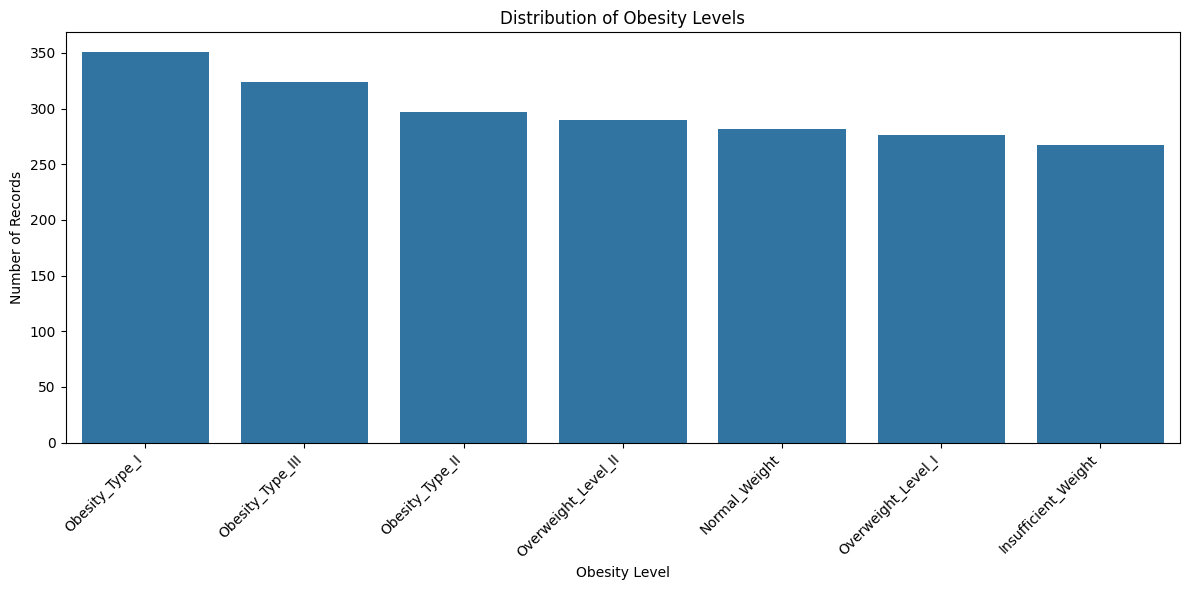

In [6]:

import matplotlib.pyplot as plt
import seaborn as sns

# Display the distribution of obesity levels
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x="NObeyesdad",
    order=df["NObeyesdad"].value_counts().index
)

plt.title("Distribution of Obesity Levels")
plt.xlabel("Obesity Level")
plt.ylabel("Number of Records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()



### Class Distribution Analysis

The chart shows that the seven obesity categories have relatively similar numbers of records. Obesity_Type_I has the largest number of samples, while Insufficient_Weight has the smallest. Overall, there is no severe class imbalance.

We will use stratified data splitting to preserve the proportion of each obesity category in the training, validation, and test sets. Accuracy and macro-averaged F1-score will be used to compare model performance across all seven classes.



### Feature Correlation Analysis

We examine the relationships between numerical features using a correlation heatmap. This helps us identify strongly related measurements and understand possible patterns in the dataset.


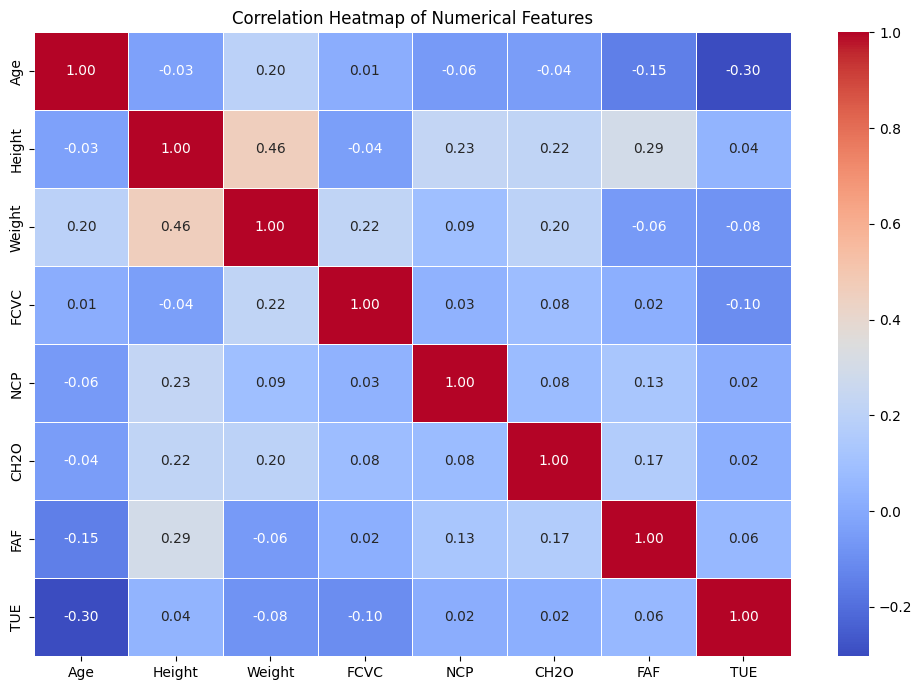

In [7]:

# Select numerical features for correlation analysis
numeric_features = df.select_dtypes(include="number")

# Calculate correlations
correlation_matrix = numeric_features.corr()

# Display the correlation heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()



### Correlation Analysis Results

The correlation heatmap shows that most numerical features have weak relationships with each other. Height and Weight have the strongest positive correlation (0.46), while Age and TUE have a negative correlation (-0.30).

These findings suggest that most numerical features provide different information. Therefore, no features will be removed based only on this correlation analysis. Feature relevance will be examined further during model development.



### Feature Distribution Analysis

We use histograms to examine the distributions of numerical features in the Obesity dataset. These graphs help us understand how the values vary and identify possible patterns or skewness.


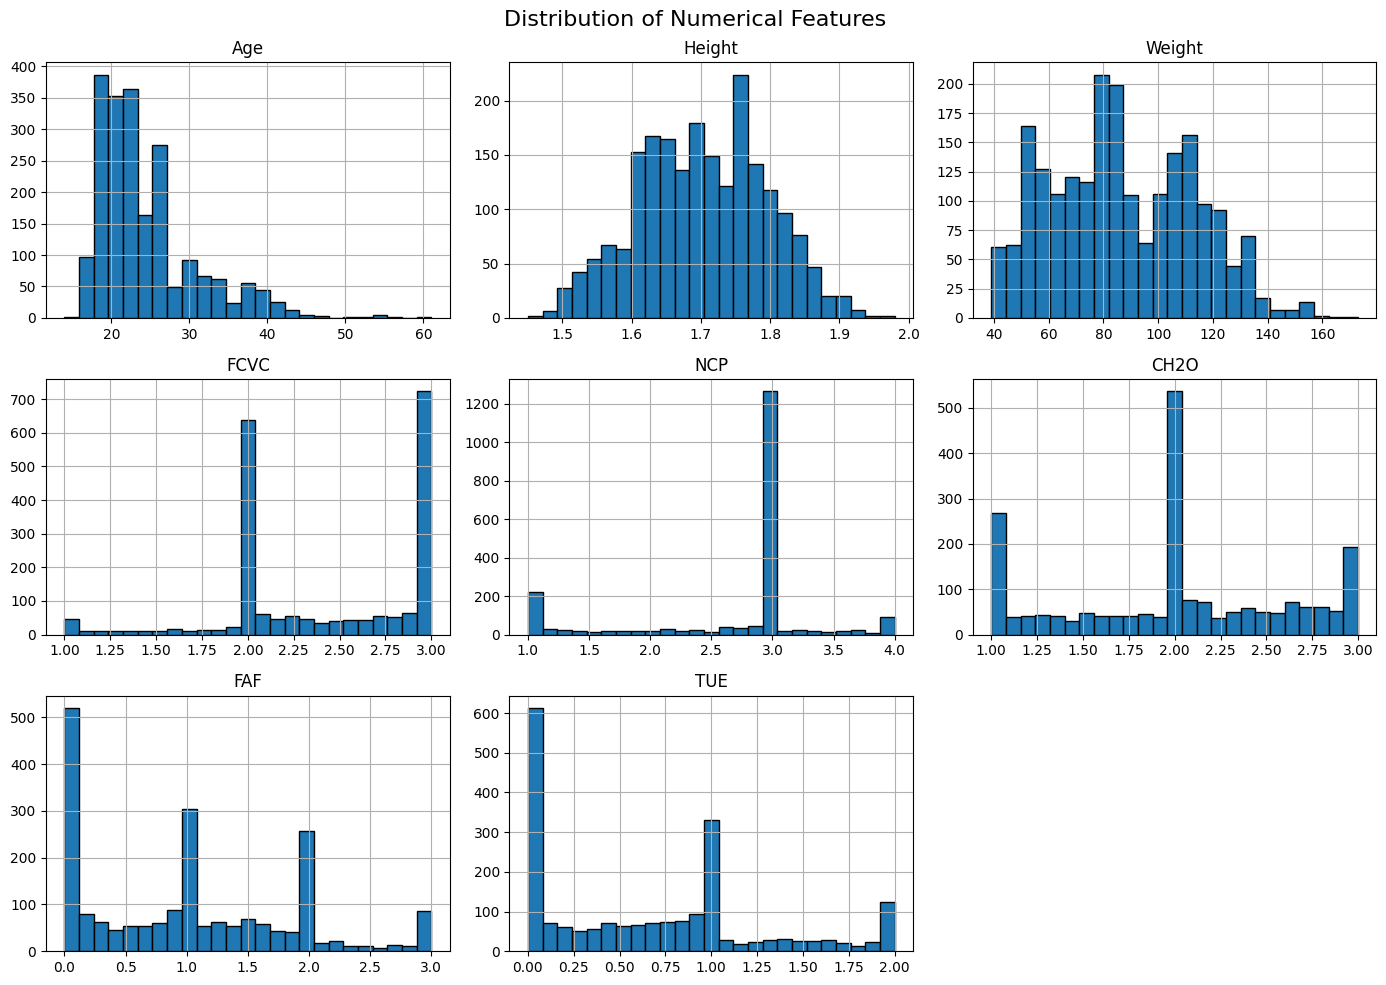

In [8]:

import matplotlib.pyplot as plt

# Select numerical features
numeric_features = df.select_dtypes(include="number")

# Plot numerical feature distributions
numeric_features.hist(
    figsize=(14, 10),
    bins=25,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()



### Feature Distribution Results

The histograms show different patterns across the numerical features. Age is concentrated among younger adults, while Height is distributed around the middle of its range. Weight has a wider distribution with several peaks.

FCVC, NCP, and CH2O show concentrations at specific values. FAF has noticeable peaks near 0, 1, and 2, while TUE is concentrated mainly around 0 and 1.

These patterns show that the features have different ranges and distributions. Appropriate encoding and scaling will be applied during model development, with data-dependent preprocessing fitted on the training data only.



### Feature Relevance Analysis

We examine how numerical features differ across the seven obesity categories. This helps us understand which measurements may be useful for prediction. Final feature selection, if needed, will use training data only to prevent data leakage.


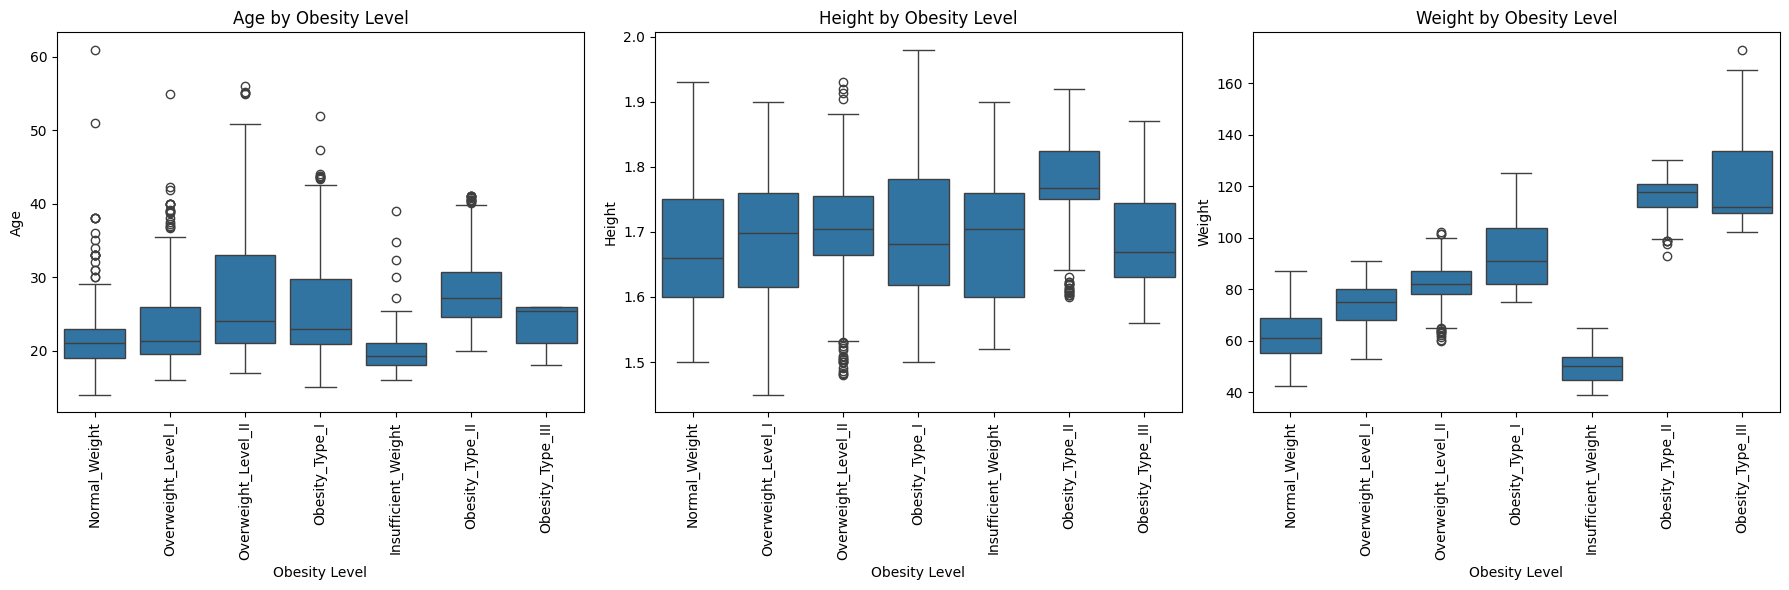

In [9]:

# Compare numerical features across obesity levels
features_to_examine = ["Age", "Height", "Weight"]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for i, feature in enumerate(features_to_examine):
    sns.boxplot(
        data=df,
        x="NObeyesdad",
        y=feature,
        ax=axes[i]
    )
    axes[i].set_title(f"{feature} by Obesity Level")
    axes[i].tick_params(axis="x", rotation=90)
    axes[i].set_xlabel("Obesity Level")

plt.tight_layout()
plt.show()



### Feature Relevance Results

The boxplots show how Age, Height, and Weight vary across the seven obesity categories. Age and Height have overlapping distributions, meaning these features alone may not clearly distinguish the classes. Weight shows clearer differences between categories and appears particularly useful for predicting obesity levels.

Since obesity categories are closely related to body measurements, especially height and weight, these relationships should be considered when interpreting model performance.

These plots provide an initial understanding of feature relevance. All features will be retained for initial model development, while any data-dependent feature selection will use training data only.



### Feature Engineering

The dataset contains 16 features related to eating habits, physical activity, and personal characteristics. We will keep the original features because they provide useful information for predicting obesity levels.

No additional features will be created at this stage. In particular, BMI will not be added because obesity categories are already closely related to height and weight.



### Encoding

The dataset contains numerical and categorical features. One-Hot Encoding will be used to convert categorical features into numerical values so they can be processed by the machine-learning models.

The target variable, NObeyesdad, contains seven obesity categories. Label Encoding will be used to convert these class names into numerical labels from 0 to 6.

Categorical feature encoding will be fitted using the training data only to prevent data leakage.



### Scaling

The numerical features have different ranges. StandardScaler will be used to standardize these features for Logistic Regression and the Neural Network.

Random Forest does not require feature scaling, so it can use the original numerical values.

Scaling will be fitted only on the training data. The same fitted transformation will then be applied to the validation and test sets.



## Stage 2: Data Splitting

The cleaned dataset is divided into 70% training, 15% validation, and 15% testing data. This ratio provides enough records for model training while keeping separate datasets for validation and final evaluation.

Stratified splitting is used to maintain similar proportions of the seven obesity categories in each set. A fixed random state is used to make the results reproducible.


In [10]:

from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop(columns=["NObeyesdad"])
y = df["NObeyesdad"]

# Split into 70% training and 30% temporary data
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Divide temporary data into validation and test sets
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Display the dataset sizes
print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

# Verify that all seven classes are represented
print("\nNumber of classes in each set:")
print("Training:", y_train.nunique())
print("Validation:", y_val.nunique())
print("Testing:", y_test.nunique())


Training set: (1460, 16)
Validation set: (313, 16)
Test set: (314, 16)

Number of classes in each set:
Training: 7
Validation: 7
Testing: 7



### Data Splitting Results

After removing 24 duplicate records, the dataset contains 2,087 records. The data was divided into 1,460 training records, 313 validation records, and 314 test records.

A 70% training, 15% validation, and 15% testing ratio was selected to provide sufficient data for learning while keeping separate datasets for model development and final evaluation.

Stratified splitting was used to maintain the proportions of the seven obesity categories. All seven classes are represented in each dataset.

The training set will be used to fit the models, the validation set will be used to monitor and compare their performance, and the test set will be reserved for final evaluation.


In [11]:

# Identify feature types using the training data
numerical_columns = X_train.select_dtypes(include="number").columns.tolist()
categorical_columns = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:", numerical_columns)
print("\nCategorical features:", categorical_columns)

print("\nNumber of numerical features:", len(numerical_columns))
print("Number of categorical features:", len(categorical_columns))


Numerical features: ['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']

Categorical features: ['Gender', 'family_history_with_overweight', 'FAVC', 'CAEC', 'SMOKE', 'SCC', 'CALC', 'MTRANS']

Number of numerical features: 8
Number of categorical features: 8



### Preprocessing Setup

The dataset contains eight numerical and eight categorical features. One-Hot Encoding will be used for categorical features.

StandardScaler will be used for numerical features in Logistic Regression and the Neural Network. Random Forest will use the original numerical values because scaling is not required.

Preprocessing will be fitted using training data only to prevent data leakage.


In [12]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Preprocessing for Logistic Regression and Neural Network
scaled_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_columns),
        ("cat", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ), categorical_columns)
    ]
)

# Preprocessing for Random Forest
tree_preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numerical_columns),
        ("cat", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ), categorical_columns)
    ]
)

print("Preprocessing configurations created successfully.")
print("No transformations have been fitted yet.")


Preprocessing configurations created successfully.
No transformations have been fitted yet.



### Most Relevant Features

We use a Random Forest model and permutation importance to identify which features contribute most to obesity level prediction. The analysis uses training data only to prevent data leakage.

All 16 features will be retained for initial model development.


,Feature,Importance
3,Weight,0.349178
0,Gender,0.144521
4,family_history_with_overweight,0.062055
14,CALC,0.024247
8,CAEC,0.018082
2,Height,0.017260
6,FCVC,0.014932
5,FAVC,0.013151
1,Age,0.012329
7,NCP,0.003151


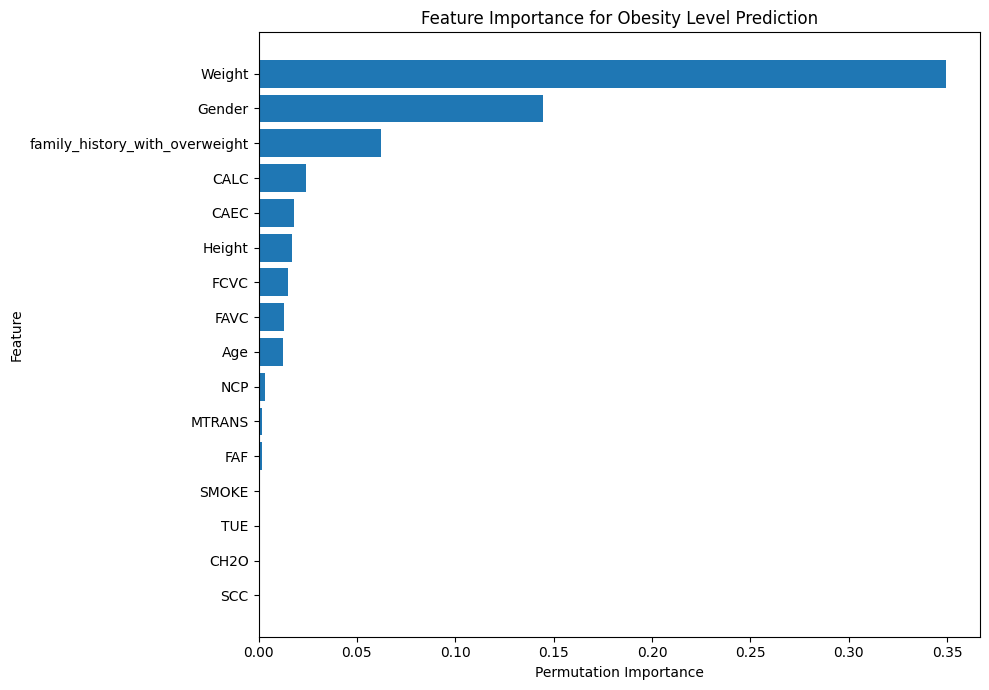

In [13]:

from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.base import clone
import pandas as pd
import matplotlib.pyplot as plt

# Create an exploratory Random Forest using training data only
rf_feature_model = Pipeline([
    ("preprocessing", clone(tree_preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

rf_feature_model.fit(X_train, y_train)

# Calculate permutation feature importance
importance_results = permutation_importance(
    rf_feature_model,
    X_train,
    y_train,
    n_repeats=5,
    random_state=42,
    scoring="accuracy"
)

# Display feature importance
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": importance_results.importances_mean
}).sort_values("Importance", ascending=False)

display(feature_importance)

# Plot feature importance
plt.figure(figsize=(10, 7))
plt.barh(
    feature_importance["Feature"][::-1],
    feature_importance["Importance"][::-1]
)
plt.xlabel("Permutation Importance")
plt.ylabel("Feature")
plt.title("Feature Importance for Obesity Level Prediction")
plt.tight_layout()
plt.show()



### Feature Importance Results

The Random Forest permutation importance analysis shows that Weight is the most influential feature, followed by Gender and family history of overweight. Other features, including CALC, CAEC, and Height, have lower importance scores.

The analysis was performed using training data only. Since obesity levels are closely related to body measurements, the high importance of Weight is expected.

All 16 features will be retained for initial model development. The final models will be evaluated using separate validation and test datasets.



## Stage 3: Model Selection and Development

Three machine-learning models are selected for predicting the seven obesity levels:

**1. Logistic Regression:** A simple classification model used as a baseline. It supports multiclass classification and helps us compare the performance of more complex models.

**2. Random Forest:** An ensemble of decision trees that can learn complex relationships between eating habits, physical characteristics, and obesity levels.

**3. Neural Network:** A model that can learn nonlinear patterns in the dataset. It uses a hidden layer with ReLU activation and an output layer with seven neurons and Softmax activation to predict the seven obesity categories.

These three models are suitable for our classification problem and will be compared using the same training, validation, and test split.


In [14]:

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
import tensorflow as tf

# Set a random seed for reproducibility
tf.keras.utils.set_random_seed(42)

# Model 1: Logistic Regression
logistic_model = Pipeline([
    ("preprocessing", clone(scaled_preprocessor)),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Model 2: Random Forest
rf_model = Pipeline([
    ("preprocessing", clone(tree_preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Model 3: Neural Network
def build_neural_network(input_dim, hidden_units=64,
                         dropout_rate=0.2, learning_rate=0.001):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(input_dim,)),
        tf.keras.layers.Dense(hidden_units, activation="relu"),
        tf.keras.layers.Dropout(dropout_rate),
        tf.keras.layers.Dense(7, activation="softmax")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

print("All three model configurations are ready.")
print("Training will be performed in Stage 4.")


All three model configurations are ready.
Training will be performed in Stage 4.



## Stage 4: Model Training and Hyperparameter Optimization

### 4.1 Logistic Regression and Random Forest

We use 5-fold stratified cross-validation to optimize the traditional machine-learning models. Macro F1-score is used to compare performance across the seven obesity categories.

Preprocessing is included inside each model pipeline to prevent data leakage during cross-validation. Only the training set is used for hyperparameter optimization.


In [15]:

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import f1_score, accuracy_score

# Define stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Hyperparameter values to test
logistic_params = {
    "classifier__C": [0.01, 0.1, 1, 10]
}

# Optimize Logistic Regression
logistic_search = GridSearchCV(
    estimator=logistic_model,
    param_grid=logistic_params,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True
)

# Train using training data only
logistic_search.fit(X_train, y_train)

# Display optimization results
print("Best parameters:", logistic_search.best_params_)
print("Best cross-validation Macro F1:",
      round(logistic_search.best_score_, 4))

# Evaluate training and validation performance
best_logistic = logistic_search.best_estimator_

train_predictions = best_logistic.predict(X_train)
val_predictions = best_logistic.predict(X_val)

print("\nTraining Macro F1:",
      round(f1_score(y_train, train_predictions, average="macro"), 4))
print("Validation Macro F1:",
      round(f1_score(y_val, val_predictions, average="macro"), 4))


Best parameters: {'classifier__C': 10}
Best cross-validation Macro F1: 0.935

Training Macro F1: 0.96
Validation Macro F1: 0.9428



### Logistic Regression Results

GridSearchCV was used with 5-fold stratified cross-validation to test four values of C: 0.01, 0.1, 1, and 10. The best value was C = 10, with a cross-validation Macro F1-score of 0.9350.

The model achieved a training Macro F1-score of 0.9600 and a validation Macro F1-score of 0.9428.

The results show good performance, with a small difference between training and validation scores. This suggests that the model generalizes reasonably well to unseen validation data, although slight overfitting may be present.



### 4.2 Random Forest

Random Forest is optimized using 5-fold stratified cross-validation. We test different numbers of trees, maximum tree depths, and minimum leaf sizes to find a suitable model while reducing the risk of overfitting.


In [16]:

# Hyperparameter values for Random Forest
rf_params = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 10],
    "classifier__min_samples_leaf": [1, 3]
}

# Optimize Random Forest using training data only
rf_search = GridSearchCV(
    estimator=rf_model,
    param_grid=rf_params,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True
)

rf_search.fit(X_train, y_train)

# Display best hyperparameters
print("Best parameters:", rf_search.best_params_)
print("Best cross-validation Macro F1:",
      round(rf_search.best_score_, 4))

# Evaluate training and validation performance
best_rf = rf_search.best_estimator_

rf_train_predictions = best_rf.predict(X_train)
rf_val_predictions = best_rf.predict(X_val)

print("\nTraining Macro F1:",
      round(f1_score(y_train, rf_train_predictions,
                     average="macro"), 4))

print("Validation Macro F1:",
      round(f1_score(y_val, rf_val_predictions,
                     average="macro"), 4))


Best parameters: {'classifier__max_depth': None, 'classifier__min_samples_leaf': 1, 'classifier__n_estimators': 100}
Best cross-validation Macro F1: 0.9311

Training Macro F1: 1.0
Validation Macro F1: 0.9417



### Random Forest Results

GridSearchCV with 5-fold stratified cross-validation was used to optimize the Random Forest model. The search tested different numbers of trees, maximum tree depths, and minimum leaf sizes.

The best cross-validation Macro F1-score was 0.9311. The model achieved a training Macro F1-score of 1.0000 and a validation Macro F1-score of 0.9417.

The perfect training score and lower validation score indicate overfitting. However, the model still performs well on validation data. The final comparison will be based on the test results of all three models.



### 4.3 Neural Network Training and Optimization

The Neural Network uses standardized numerical features and one-hot encoded categorical features. The preprocessing transformations are fitted on the training data only.

The seven obesity categories are converted into numerical labels. The validation set will be used to monitor training performance and identify overfitting or underfitting.


In [17]:

from sklearn.preprocessing import LabelEncoder
from sklearn.base import clone

# Confirm the complete Random Forest hyperparameters
print("Best Random Forest parameters:")
print(rf_search.best_params_)

# Fit Neural Network preprocessing on training data only
nn_preprocessor = clone(scaled_preprocessor)

X_train_nn = nn_preprocessor.fit_transform(X_train)
X_val_nn = nn_preprocessor.transform(X_val)

# Encode target labels
label_encoder = LabelEncoder()

y_train_nn = label_encoder.fit_transform(y_train)
y_val_nn = label_encoder.transform(y_val)

# Verify prepared data
print("\nTraining features:", X_train_nn.shape)
print("Validation features:", X_val_nn.shape)
print("Training labels:", y_train_nn.shape)
print("Validation labels:", y_val_nn.shape)
print("Number of classes:", len(label_encoder.classes_))


Best Random Forest parameters:
{'classifier__max_depth': None, 'classifier__min_samples_leaf': 1, 'classifier__n_estimators': 100}

Training features: (1460, 31)
Validation features: (313, 31)
Training labels: (1460,)
Validation labels: (313,)
Number of classes: 7


Epochs completed: 100
Training Macro F1: 0.9956
Validation Macro F1: 0.9577


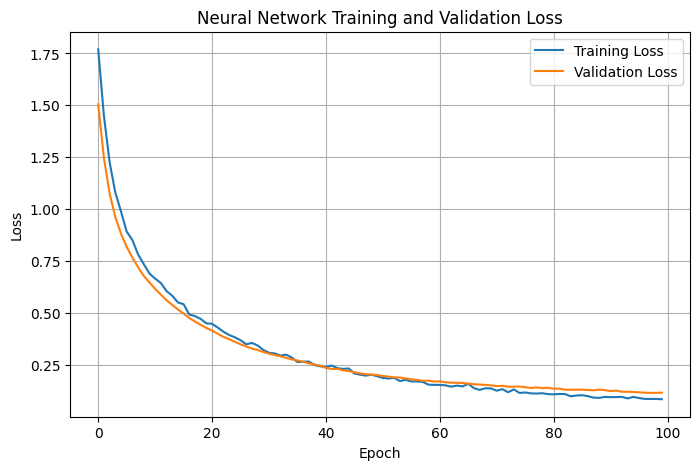

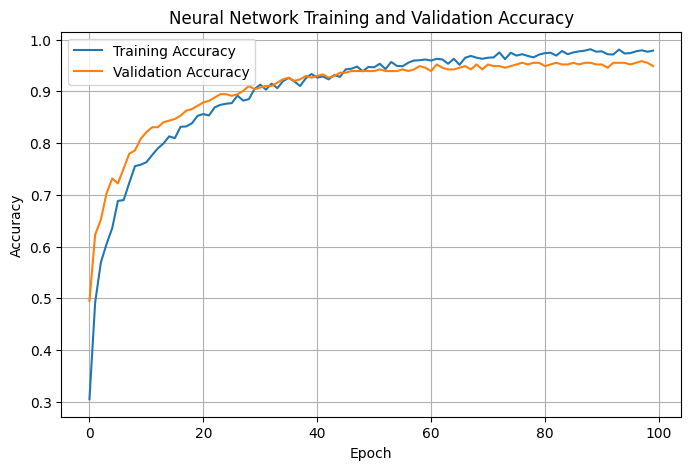

In [18]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score

# Set seed for reproducibility
tf.keras.utils.set_random_seed(42)

# Build the Neural Network
nn_model = build_neural_network(
    input_dim=X_train_nn.shape[1],
    hidden_units=64,
    dropout_rate=0.2,
    learning_rate=0.001
)

# Stop training when validation loss stops improving
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=12,
    restore_best_weights=True
)

# Train the Neural Network
history = nn_model.fit(
    X_train_nn,
    y_train_nn,
    validation_data=(X_val_nn, y_val_nn),
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=0
)

# Evaluate training and validation performance
nn_train_pred = np.argmax(
    nn_model.predict(X_train_nn, verbose=0), axis=1
)
nn_val_pred = np.argmax(
    nn_model.predict(X_val_nn, verbose=0), axis=1
)

print("Epochs completed:", len(history.history["loss"]))
print("Training Macro F1:",
      round(f1_score(y_train_nn, nn_train_pred,
                     average="macro"), 4))
print("Validation Macro F1:",
      round(f1_score(y_val_nn, nn_val_pred,
                     average="macro"), 4))

# Training and validation loss curves
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Neural Network Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

# Training and validation accuracy curves
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"],
         label="Training Accuracy")
plt.plot(history.history["val_accuracy"],
         label="Validation Accuracy")
plt.title("Neural Network Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()



### Neural Network Baseline Results

The Neural Network was trained for 100 epochs using 64 hidden neurons, a dropout rate of 0.2, and a learning rate of 0.001.

The model achieved a training Macro F1-score of 0.9956 and a validation Macro F1-score of 0.9577.

Both training and validation loss decreased during training, while accuracy improved and gradually stabilized. The difference between training and validation performance suggests some overfitting, but the model still performs well on validation data.

The baseline results will be compared with other Neural Network configurations to determine whether hyperparameter tuning can improve generalization.



### 4.4 Neural Network Hyperparameter Optimization

We compare three Neural Network configurations with different numbers of hidden neurons and dropout rates. The goal is to improve validation performance while reducing overfitting.

All configurations use the same training and validation datasets, Adam optimizer, and learning rate of 0.001. Early stopping is used to restore the weights from the epoch with the lowest validation loss.

The best configuration will be selected using the validation Macro F1-score. The test dataset will be reserved for final evaluation.


In [19]:

import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import f1_score

# Keep the existing baseline model and training history
nn_candidates = [
    {
        "Name": "Baseline",
        "Neurons": 64,
        "Dropout": 0.2,
        "Model": nn_model,
        "History": history
    }
]

# Test two additional configurations
configurations = [
    ("Model 2", 32, 0.2),
    ("Model 3", 128, 0.3)
]

for name, neurons, dropout in configurations:

    tf.keras.utils.set_random_seed(42)

    model = build_neural_network(
        input_dim=X_train_nn.shape[1],
        hidden_units=neurons,
        dropout_rate=dropout,
        learning_rate=0.001
    )

    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=12,
        restore_best_weights=True
    )

    model_history = model.fit(
        X_train_nn,
        y_train_nn,
        validation_data=(X_val_nn, y_val_nn),
        epochs=100,
        batch_size=32,
        callbacks=[early_stop],
        verbose=0
    )

    nn_candidates.append({
        "Name": name,
        "Neurons": neurons,
        "Dropout": dropout,
        "Model": model,
        "History": model_history
    })

# Compare all three configurations
results = []

for candidate in nn_candidates:

    model = candidate["Model"]

    train_pred = np.argmax(
        model.predict(X_train_nn, verbose=0), axis=1
    )

    val_pred = np.argmax(
        model.predict(X_val_nn, verbose=0), axis=1
    )

    results.append({
        "Model": candidate["Name"],
        "Neurons": candidate["Neurons"],
        "Dropout": candidate["Dropout"],
        "Epochs": len(candidate["History"].history["loss"]),
        "Training Macro F1": f1_score(
            y_train_nn, train_pred, average="macro"
        ),
        "Validation Macro F1": f1_score(
            y_val_nn, val_pred, average="macro"
        )
    })

nn_tuning_results = pd.DataFrame(results)

display(nn_tuning_results.round(4))

# Select the model with the highest validation Macro F1
best_index = nn_tuning_results["Validation Macro F1"].idxmax()

best_nn_model = nn_candidates[best_index]["Model"]
best_nn_history = nn_candidates[best_index]["History"]

print("\nBest Neural Network:", nn_candidates[best_index]["Name"])
print("Best validation Macro F1:",
      round(nn_tuning_results.loc[best_index, "Validation Macro F1"], 4))


,Model,Neurons,Dropout,Epochs,Training Macro F1,Validation Macro F1
0,Baseline,64,0.2,100,0.9956,0.9577
1,Model 2,32,0.2,100,0.9797,0.9379
2,Model 3,128,0.3,100,0.9985,0.9639



Best Neural Network: Model 3
Best validation Macro F1: 0.9639



### Best Neural Network Training and Validation Curves

Model 3 achieved the highest validation Macro F1-score (0.9639). It uses 128 hidden neurons, a dropout rate of 0.3, and a learning rate of 0.001.

We examine its training and validation loss and accuracy curves to understand learning performance and possible overfitting.


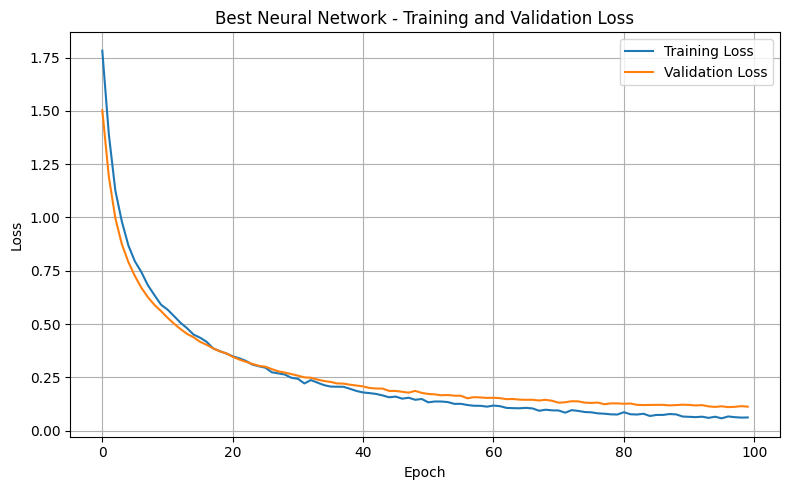

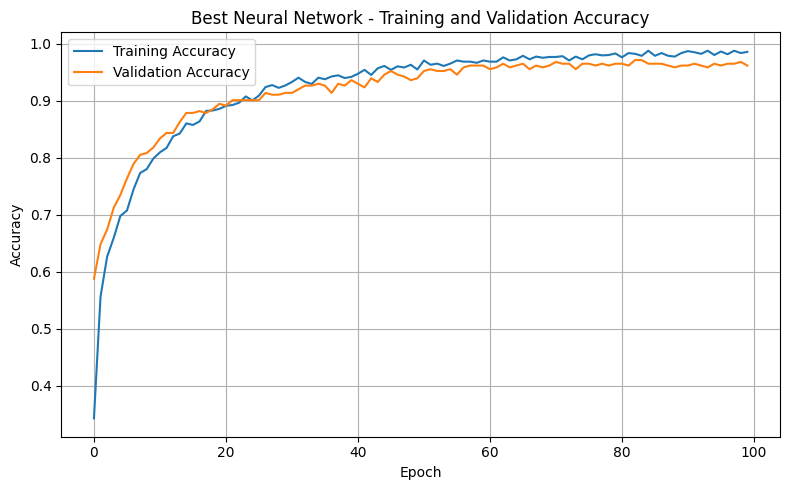

In [20]:

# Training and validation loss for the best Neural Network
plt.figure(figsize=(8, 5))
plt.plot(best_nn_history.history["loss"], label="Training Loss")
plt.plot(best_nn_history.history["val_loss"], label="Validation Loss")
plt.title("Best Neural Network - Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Training and validation accuracy for the best Neural Network
plt.figure(figsize=(8, 5))
plt.plot(best_nn_history.history["accuracy"], label="Training Accuracy")
plt.plot(best_nn_history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Best Neural Network - Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



### Neural Network Optimization Results

Three Neural Network configurations were compared using different hidden-layer sizes and dropout rates. Model 3 achieved the highest validation Macro F1-score of 0.9639, using 128 hidden neurons and a dropout rate of 0.3.

The training and validation loss curves decreased steadily, while accuracy improved and gradually stabilized. The model achieved a training Macro F1-score of 0.9985, indicating a small gap between training and validation performance.

Although some overfitting is present, the model performs well on validation data. Dropout was used to reduce overfitting, and early stopping was included to monitor validation loss.

Model 3 was selected for final evaluation because it achieved the best validation Macro F1-score among the tested configurations.



## Stage 5: Model Final Evaluation and Comparison

The three selected models are evaluated using the test set, which was not used during training or hyperparameter optimization.

Accuracy, Macro Precision, Macro Recall, and Macro F1-score are used to measure model performance. Macro-averaged metrics give equal importance to all seven obesity categories.

Classification reports and confusion matrices are also used to examine individual class performance and classification errors.


Final Test Set Comparison:


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Logistic Regression,0.9427,0.9408,0.9398,0.9395
1,Random Forest,0.9331,0.9333,0.9298,0.9311
2,Neural Network,0.9490,0.9475,0.9454,0.9458



Logistic Regression - Classification Report:
                     precision    recall  f1-score   support

Insufficient_Weight       0.93      1.00      0.96        40
      Normal_Weight       0.97      0.86      0.91        42
     Obesity_Type_I       0.98      0.98      0.98        53
    Obesity_Type_II       0.98      0.98      0.98        45
   Obesity_Type_III       1.00      1.00      1.00        49
 Overweight_Level_I       0.85      0.85      0.85        41
Overweight_Level_II       0.87      0.91      0.89        44

           accuracy                           0.94       314
          macro avg       0.94      0.94      0.94       314
       weighted avg       0.94      0.94      0.94       314



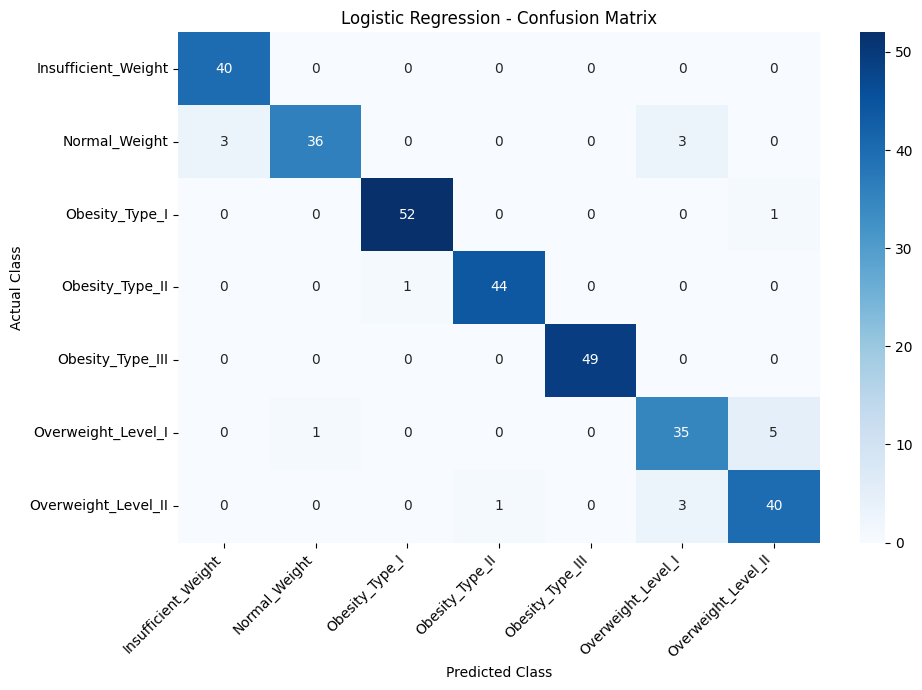


Random Forest - Classification Report:
                     precision    recall  f1-score   support

Insufficient_Weight       0.97      0.93      0.95        40
      Normal_Weight       0.80      0.88      0.84        42
     Obesity_Type_I       0.93      0.96      0.94        53
    Obesity_Type_II       1.00      0.98      0.99        45
   Obesity_Type_III       1.00      1.00      1.00        49
 Overweight_Level_I       0.90      0.85      0.88        41
Overweight_Level_II       0.93      0.91      0.92        44

           accuracy                           0.93       314
          macro avg       0.93      0.93      0.93       314
       weighted avg       0.94      0.93      0.93       314



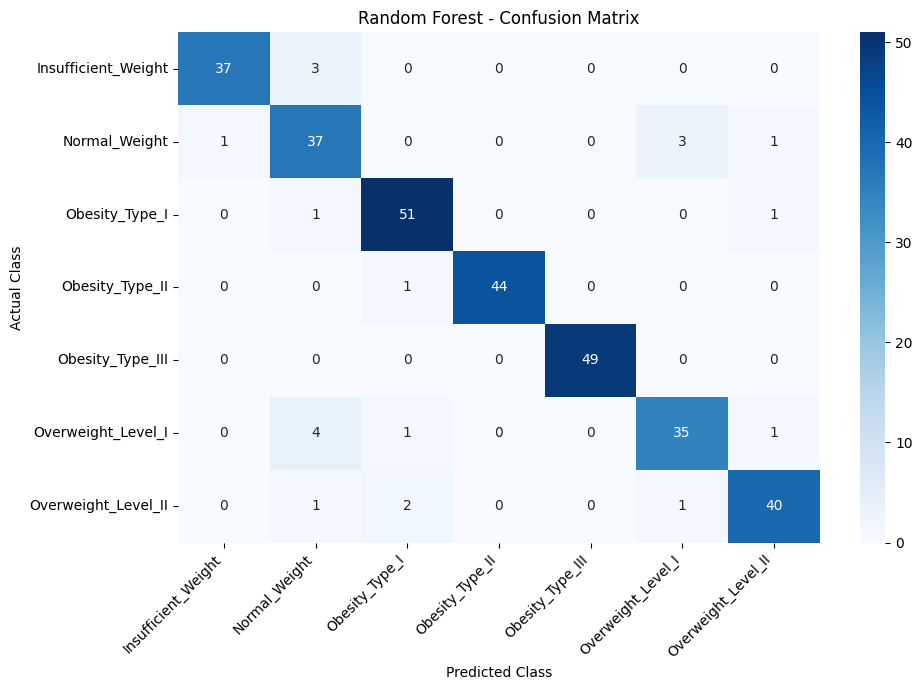


Neural Network - Classification Report:
                     precision    recall  f1-score   support

Insufficient_Weight       0.97      0.95      0.96        40
      Normal_Weight       0.92      0.83      0.88        42
     Obesity_Type_I       0.98      1.00      0.99        53
    Obesity_Type_II       1.00      0.98      0.99        45
   Obesity_Type_III       1.00      1.00      1.00        49
 Overweight_Level_I       0.82      0.90      0.86        41
Overweight_Level_II       0.93      0.95      0.94        44

           accuracy                           0.95       314
          macro avg       0.95      0.95      0.95       314
       weighted avg       0.95      0.95      0.95       314



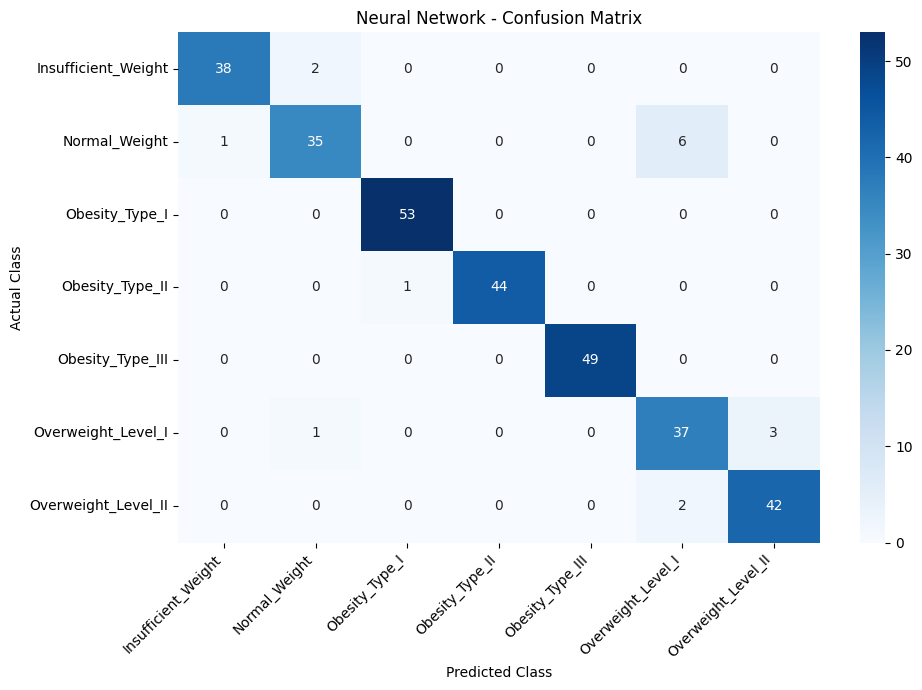

In [21]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Final test predictions
logistic_test_pred = best_logistic.predict(X_test)
rf_test_pred = best_rf.predict(X_test)

# Neural Network: use the fitted training preprocessor
X_test_nn = nn_preprocessor.transform(X_test)

nn_probabilities = best_nn_model.predict(
    X_test_nn, verbose=0
)

nn_encoded_predictions = np.argmax(
    nn_probabilities, axis=1
)

nn_test_pred = label_encoder.inverse_transform(
    nn_encoded_predictions
)

# Collect model predictions
test_predictions = {
    "Logistic Regression": logistic_test_pred,
    "Random Forest": rf_test_pred,
    "Neural Network": nn_test_pred
}

# Calculate evaluation metrics
results = []

for name, predictions in test_predictions.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro Precision": precision_score(
            y_test, predictions, average="macro",
            zero_division=0
        ),
        "Macro Recall": recall_score(
            y_test, predictions, average="macro",
            zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, predictions, average="macro",
            zero_division=0
        )
    })

test_results = pd.DataFrame(results)

print("Final Test Set Comparison:")
display(test_results.round(4))

# Classification reports and confusion matrices
class_names = list(label_encoder.classes_)

for name, predictions in test_predictions.items():

    print(f"\n{name} - Classification Report:")
    print(classification_report(
        y_test,
        predictions,
        labels=class_names,
        zero_division=0
    ))

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=class_names
    )

    plt.figure(figsize=(10, 7))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.title(f"{name} - Confusion Matrix")
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()



### Final Model Comparison Results

The three models were evaluated using the independent test set containing 314 records.

The Neural Network achieved the highest overall performance, with an accuracy of 0.9490 and a Macro F1-score of 0.9458. Logistic Regression followed with an accuracy of 0.9427 and a Macro F1-score of 0.9395. Random Forest achieved an accuracy of 0.9331 and a Macro F1-score of 0.9311.

The classification reports and confusion matrices show that all three models performed well in predicting the seven obesity categories. Obesity_Type_III was classified correctly in all test cases, while some errors occurred between Normal Weight and Overweight categories.

The Neural Network was selected during development because it achieved the highest validation Macro F1-score. Its final test results also show the best overall performance among the three models.

However, the differences between the models are relatively small. The results should also be interpreted carefully because obesity levels are closely related to height and weight, and the dataset contains synthetic observations.
